# Plot detection in a UAV potato-trial NDVI orthomosaic

**Paper:** *Prediction of late blight severity in a large panel of potato genotypes using low-altitude aerial images and machine learning methods*, PLOS ONE 21(11):e0347446 (2026-11-03). DOI: [10.1371/journal.pone.0347446](https://doi.org/10.1371/journal.pone.0347446) (CC BY).

**Author code reproduced here (smallest runnable subsection):** the authors' MATLAB plot-detection scripts — [`ObjectsDetection.m`](https://github.com/hildomaclean/Plots-Potato-detection/blob/681f15bd24b1169776d15990c87ce29f8d1a90d1/ObjectsDetection.m) and [`Retrieving_PixelsInformation.m`](https://github.com/hildomaclean/Plots-Potato-detection/blob/681f15bd24b1169776d15990c87ce29f8d1a90d1/Retrieving_PixelsInformation.m) — which detect potato plots in a UAV orthomosaic grid, label them, and retrieve per-plot NDVI pixel statistics.

**Scope:** a *partial* demonstration on the single author-provided sample grid (`20191129_40m_ndvi_CUT_BIN_027_FILTER_GRID1.tif`, Trial-B flight imagery). This notebook does **not** reproduce the paper's K-means+KRR severity models, mixed-model BLUEs, or selection-coincidence analysis: their imagery inputs and fitted parameters are not publicly deposited.

> **ADAPTED PYTHON DEMONSTRATION — AI-assisted translation from MATLAB.** The authors did not provide this Colab implementation (the repository is MATLAB-only and has no license file). The ported operations and checks below were executed and validated on the author's own sample image, but untested behavior is not guaranteed. The binary detection mask in `ObjectsDetection.m` is built from an RGB image (`20191129_40m_RGB_CUT_GRID1_RGB_255.tif`) that is **not present** in the repository; this notebook therefore derives the mask from the deposited NDVI image using the authors' own vegetation convention (`NDVI > 0`, see `Retrieving_PixelsInformation.m`), documented in the cells below.

**日本語:** このノートブックは、ジャガイモ晩疫病論文（PLOS ONE 2026）の著者公開 MATLAB コードの最小実行サブセクション（圃場プロット検出とプロット別 NDVI 統計の抽出）を Python に移植したものです。著者は Colab 実装を公開していないため AI による翻訳です（ADAPTED PYTHON DEMONSTRATION）。検出用の RGB 画像はリポジトリに存在しないため、著者コードと同じ「NDVI > 0 を植被」という規準で NDVI 画像からマスクを作成します。完全な論文再現（K-means+KRR 重度推定や混合モデル等）は、必要な画像・学習済みパラメータが公開されていないため対象外です。

## Runtime selection

This notebook is a **CPU-only** demonstration: it performs 2-D connected-component labeling and plotting on one ~9.5 MB single-band GeoTIFF. No deep-learning framework or GPU operation is involved, so a GPU runtime adds nothing.

**Select `Runtime → Change runtime type → CPU` in Colab, then `Runtime → Run all`.**

Expected duration: a few minutes total (mostly dependency checks and the single image download, well under 20 MB). All scientific downloads and execution happen inside this notebook on the Colab VM.

**日本語:** このノートブックは CPU のみで動作します（9.5 MB 程度の単バンド GeoTIFF に対する連結成分ラベリングと描画のみ）。GPU は不要です。ランタイムを CPU に設定して「すべてのセルを実行」してください。所要時間は数分、ダウンロードは 20 MB 未満です。

## 1. Environment check

We verify the Python version and required libraries. `numpy`, `scipy`, and `matplotlib` are preinstalled on Colab; `tifffile` reads the authors' GeoTIFF and is normally present, but we install it explicitly if missing (pinned to a recent stable release).

**日本語:** Python と必要ライブラリの確認です。`numpy`/`scipy`/`matplotlib` は Colab に標準搭載、`tifffile` は無ければインストールします。

In [ ]:
import sys, importlib.util, subprocess
print('Python:', sys.version)
for pkg in ['numpy', 'scipy', 'matplotlib', 'tifffile', 'pandas']:
    spec = importlib.util.find_spec(pkg)
    print(f'{pkg}:', 'available' if spec else 'MISSING')
try:
    import tifffile
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tifffile>=2024.0.0'], check=True)
    import tifffile
print('tifffile version:', tifffile.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
numpy: available
scipy: available
matplotlib: available
tifffile: available
pandas: available


tifffile version: 2026.10.15


## 2. Acquire the author's sample input (Colab-only download)

The sample input is a **dataset payload**, so it is downloaded here inside Colab (never on the authoring host) from the pinned author repository revision `681f15bd24b1169776d15990c87ce29f8d1a90d1` of `hildomaclean/Plots-Potato-detection`. We validate the bytes by size and by the Git blob SHA-1 (`sha1('blob <size>\\0' + bytes)`), which must equal the repository's recorded blob hash `196b5e7e654ebeb487ee97181e2e14dc7f3c226f`. This rejects any HTML error page saved under a `.tif` name.

**日本語:** 著者リポジトリ（コミット `681f15b` 固定）からサンプル NDVI オルソモザイクを Colab 内でダウンロードし、サイズと Git blob SHA-1（`196b5e7e…`）でバイト列を検証します。

In [ ]:
import urllib.request, hashlib, os
COMMIT = '681f15bd24b1169776d15990c87ce29f8d1a90d1'
FNAME = '20191129_40m_ndvi_CUT_BIN_027_FILTER_GRID1.tif'
EXPECTED_SHA1 = '196b5e7e654ebeb487ee97181e2e14dc7f3c226f'
URL = f'https://raw.githubusercontent.com/hildomaclean/Plots-Potato-detection/{COMMIT}/{FNAME}'
DEST = f'/content/{FNAME}'

urllib.request.urlretrieve(URL, DEST)  # bounded single GET of the pinned raw URL
raw = open(DEST, 'rb').read()
print('downloaded bytes:', len(raw))
assert not raw.lstrip().startswith(b'<'), 'refusing HTML error page saved as .tif'
blob_sha1 = hashlib.sha1(b'blob %d\0' % len(raw) + raw).hexdigest()
print('git blob sha1:', blob_sha1)
assert blob_sha1 == EXPECTED_SHA1, 'pinned blob hash mismatch — download is not the author sample'
print('OK: byte-identical to the pinned author sample')

downloaded bytes: 9482928
git blob sha1: 196b5e7e654ebeb487ee97181e2e14dc7f3c226f
OK: byte-identical to the pinned author sample


## 3. Inspect the NDVI raster

The sample is a single-band float32 NDVI orthomosaic. The file carries a GDAL NODATA sentinel of `-3.4e38`; the authors' retrieval script treats **all** negative pixels as "without data" (`nul1`), zero pixels separately (`cer1`), and `NDVI > 0` as vegetation (`plan1`). We reproduce exactly that value classification below. Note that a plain `mean()` over the raw array is `-inf` because of the sentinel, so summaries must use masked statistics.

**日本語:** サンプルは float32 の単バンド NDVI 画像です。ノーデータ哨戒値（-3.4e38）があり、著者コードと同様に「負=データなし・0・正=植被」の 3 分類で集計します（生の mean は -inf になるためマスク統計を使用）。

In [ ]:
import numpy as np, tifffile
ndvi = tifffile.imread(DEST)
print('shape (rows, cols):', ndvi.shape, '| dtype:', ndvi.dtype)
finite = ndvi[np.abs(ndvi) < 1e6]  # exclude the -3.4e38 NODATA sentinel
print('valid-pixel range:', float(finite.min()), 'to', round(float(finite.max()), 4))
print('fraction <0 (incl. NODATA):', round(float((ndvi < 0).mean()), 4))
print('fraction ==0            :', round(float((ndvi == 0).mean()), 4))
print('fraction >0 (vegetation):', round(float((ndvi > 0).mean()), 4))

shape (rows, cols): (2449, 967) | dtype: float32
valid-pixel range: 0.0 to 0.9338
fraction <0 (incl. NODATA): 0.8813
fraction ==0            : 0.0261
fraction >0 (vegetation): 0.0926


## 4. Input preview

Before any analysis we display the actual sample: vegetation pixels (NDVI > 0) in green over a grey background, with the no-data areas masked. The rectangular field grid of potato plots is directly visible. This preview uses only the downloaded author sample — nothing is synthesized.

**日本語:** 解析前に実際のサンプル画像を表示します（NDVI>0 を緑、背景は灰色、ノーデータはマスク）。矩形の試験区グリッドが見えます。

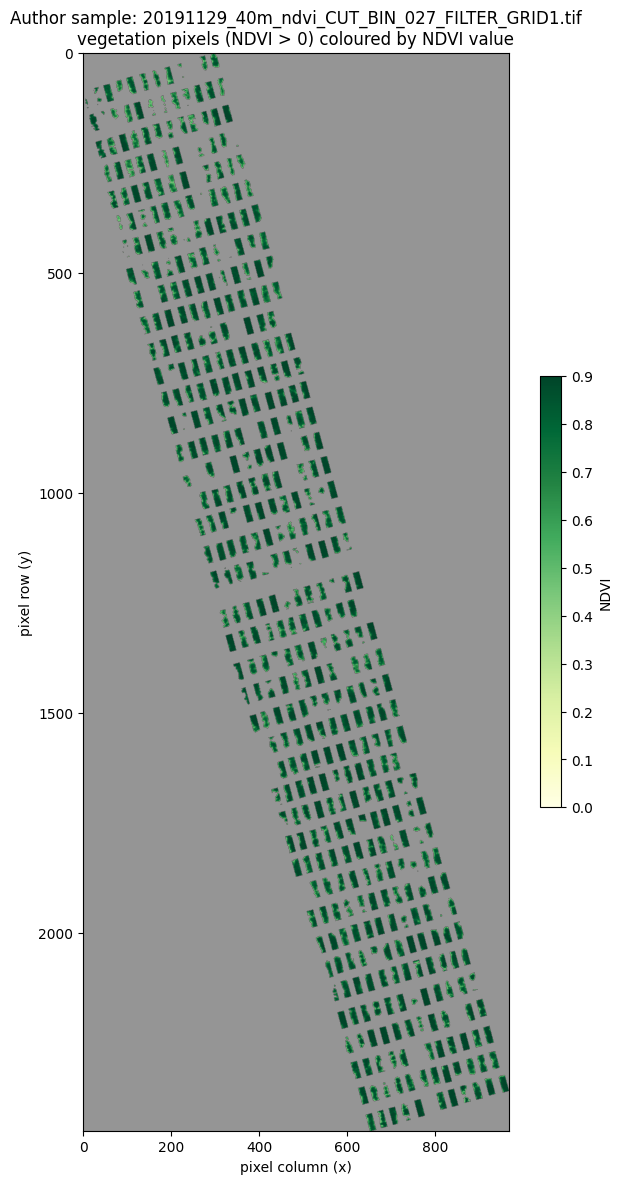

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 14))
bg = np.where(ndvi > 0, np.nan, 0.0)  # grey background under vegetation
ax.imshow(bg, cmap='Greys', vmin=-1, vmax=1)
im = ax.imshow(np.where(ndvi > 0, ndvi, np.nan), cmap='YlGn', vmin=0, vmax=0.9)
ax.set_title("Author sample: 20191129_40m_ndvi_CUT_BIN_027_FILTER_GRID1.tif\nvegetation pixels (NDVI > 0) coloured by NDVI value")
ax.set_xlabel('pixel column (x)'); ax.set_ylabel('pixel row (y)')
fig.colorbar(im, ax=ax, shrink=0.4, label='NDVI')
plt.show()

## 5. Plot detection — port of `ObjectsDetection.m` (adapted)

`ObjectsDetection.m` binarizes an RGB grid image (`rgb2gray` → `im2bw` at 0.5) and calls `regionprops(bw, 'Perimeter','Area','Centroid','BoundingBox')`, then draws a labelled rectangle around every detected region over the NDVI image. That RGB image is absent from the repository, so we **adapt** the mask step: binary mask = `NDVI > 0` (the authors' own vegetation convention in `Retrieving_PixelsInformation.m`), then `scipy.ndimage.label` + `find_objects` provide the same Perimeter-implicit, Area, Centroid, and BoundingBox properties.

Plot-sized regions are ≈470–570 px in this grid; smaller fragments (rows/edges broken by no-data gaps) are excluded with a documented **minimum area of 100 px** (~21% of the median plot area). The printed size distribution shows exactly what this cut removes.

**日本語:** 著者の `ObjectsDetection.m` は RGB 画像の二値化＋`regionprops` で矩形検出しますが、その RGB 画像はリポジトリに無いため、NDVI>0 のマスクから `scipy.ndimage` で同一性質（面積・重心・外接矩形）を求める適応版です。面積 100 px 未満の断片（プロット実測サイズは約 470–570 px）は除外し、その根拠分布を表示します。

In [ ]:
from scipy import ndimage
mask = ndvi > 0
labels, n_regions = ndimage.label(mask)
slices_all = ndimage.find_objects(labels)
sizes_all = np.bincount(labels.ravel())[1:]
print('connected regions (NDVI > 0):', n_regions)
print('region area percentiles 50/90/99/max:',
      np.percentile(sizes_all, [50, 90, 99]).astype(int).tolist(), int(sizes_all.max()))

MIN_AREA = 100  # documented adaptation; plot-sized regions are ~470-570 px here
keep = [i for i, sl in enumerate(slices_all) if sizes_all[i] >= MIN_AREA]
print(f'regions kept with area >= {MIN_AREA} px:', len(keep))
print('removed fragments:', n_regions - len(keep))

connected regions (NDVI > 0): 574
region area percentiles 50/90/99/max: [476, 571, 572] 574
regions kept with area >= 100 px: 463
removed fragments: 111


## 6. Detected-plot overlay — output of the ported `ObjectsDetection.m`

Exactly as the authors' script does, we draw every detected plot's bounding box (blue) and its region index at the centroid (red) on top of the NDVI image. This is the core visual result of the reproduction: the flight image with its detected, labelled experimental plots.

**日本語:** 著者スクリプトと同様に、検出された各プロットの外接矩形（青）と領域番号（赤）を NDVI 画像上に重ねて表示します。これが本再現の中心出力です。

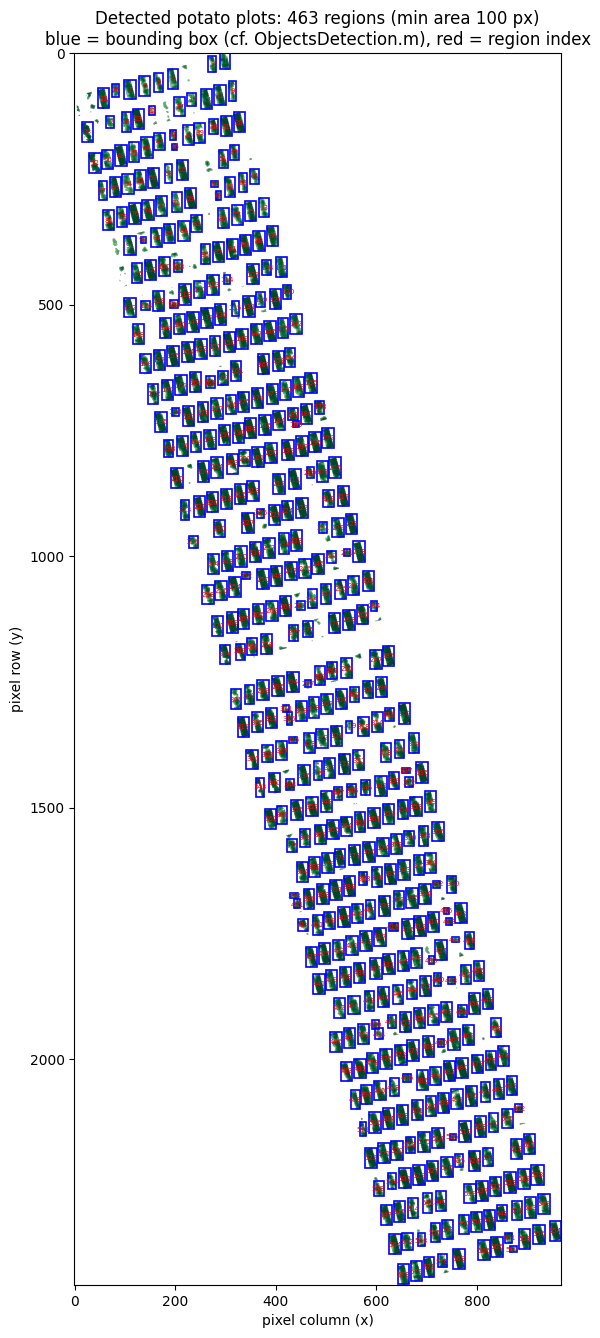

In [ ]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(9, 16))
ax.imshow(np.where(ndvi > 0, ndvi, np.nan), cmap='YlGn', vmin=0, vmax=0.9)
for i in keep:
    sl = slices_all[i]
    y0, y1 = sl[0].start, sl[0].stop - 1   # MATLAB BoundingBox: [x y w h], y along rows
    x0, x1 = sl[1].start, sl[1].stop - 1
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                           edgecolor='b', facecolor='none', linewidth=1.2))
    cy, cx = ndimage.center_of_mass(mask, labels, i + 1)
    ax.text(cx, cy, str(i + 1), color='r', fontsize=5, ha='center', va='center')
ax.set_title(f'Detected potato plots: {len(keep)} regions (min area {MIN_AREA} px)\n' +
             'blue = bounding box (cf. ObjectsDetection.m), red = region index')
ax.set_xlabel('pixel column (x)'); ax.set_ylabel('pixel row (y)')
plt.show()

## 7. Per-plot pixel retrieval — port of `Retrieving_PixelsInformation.m`

The authors' second script loops over every detected **bounding rectangle** and classifies all of its NDVI pixels into the authors' `gri1` grid: `< 0` → no-data (`nul1`), `== 0` → zero (`cer1`), `> 0` → vegetation (`plan1`/`grif1`). Because our mask is built from `NDVI > 0`, the region pixels themselves are vegetation by construction; the rectangle-level counts are what capture the gaps inside each plot's bounding box, exactly as in the authors' script. We also add each plot's mean NDVI over its vegetation pixels — the plot-level NDVI quantity the paper correlates with visually assessed severity (Materials and methods, *Late blight severity estimation*).

**日本語:** `Retrieving_PixelsInformation.m` の移植です。著者コードと同じく各プロットの**外接矩形内の全ピクセル**を「負（ノーデータ）・0・正（植被）」に分類し（`nul1`/`cer1` 相当）、植被ピクセルの平均 NDVI（論文の小区画 NDVI 相当）を併せて計算します。

In [ ]:
import pandas as pd
rows = []
for i in keep:
    sl = slices_all[i]
    rect = ndvi[sl[0].start:sl[0].stop, sl[1].start:sl[1].stop]  # full rectangle, as in the authors' gri1
    n_nodata = int((rect < 0).sum())          # nul1: pixels without data
    n_zero = int((rect == 0).sum())           # cer1: zero pixels
    veg = rect[rect > 0]                      # grif1: vegetation pixels
    rows.append({
        'region_index': i + 1,
        'bbox_row0': sl[0].start, 'bbox_col0': sl[1].start,
        'bbox_row1': sl[0].stop - 1, 'bbox_col1': sl[1].stop - 1,
        'total_pixels': int(rect.size),       # totpix1: rectangle area
        'n_nodata_lt0': n_nodata, 'n_zero': n_zero, 'n_vegetation_gt0': int(veg.size),
        'vegetation_fraction': round(float(veg.size / rect.size), 4),
        'mean_ndvi_vegetation': round(float(veg.mean()), 4),
    })
plots = pd.DataFrame(rows)
print('plots table:', plots.shape)
plots.head(10)

plots table: (463, 11)


,region_index,bbox_row0,bbox_col0,bbox_row1,bbox_col1,total_pixels,n_nodata_lt0,n_zero,n_vegetation_gt0,vegetation_fraction,mean_ndvi_vegetation
0,1,1,289,32,308,640,174,38,428,0.6687,0.7177
1,2,6,265,38,281,561,126,139,296,0.5276,0.6625
2,4,31,185,71,206,902,343,83,476,0.5277,0.6965
3,5,40,158,77,176,722,201,161,360,0.4986,0.6843
4,6,46,128,85,149,880,317,153,410,0.4659,0.6654
5,7,53,98,92,121,960,394,17,549,0.5719,0.7371
6,9,56,306,96,321,656,157,159,340,0.5183,0.6100
7,10,61,75,87,89,405,63,64,278,0.6864,0.6406
8,11,64,277,104,300,984,413,24,547,0.5559,0.7684
9,12,70,46,110,69,984,413,2,569,0.5783,0.7978


## 8. Summary of the detected plots

A compact overview of the per-plot measurements: how completely each detected plot is covered by vegetation and what its mean vegetation NDVI is. The mean-NDVI distribution below is an **additional visualization created for this notebook** (not an author figure): it shows the spread of the plot-level NDVI values that the paper would correlate with visual severity scores.

**日本語:** 検出プロットの計測値（植被率・植被ピクセル平均 NDVI）の要約です。NDVI の分布図は本ノートブック用に追加作成した補助的な可視化であり、著者の図ではありません。

       vegetation_fraction  mean_ndvi_vegetation
count             463.0000              463.0000
mean                0.5772                0.7744
std                 0.0543                0.0730
min                 0.3504                0.4950
25%                 0.5548                0.7262
50%                 0.5793                0.7813
75%                 0.5982                0.8311
max                 0.7807                0.9096


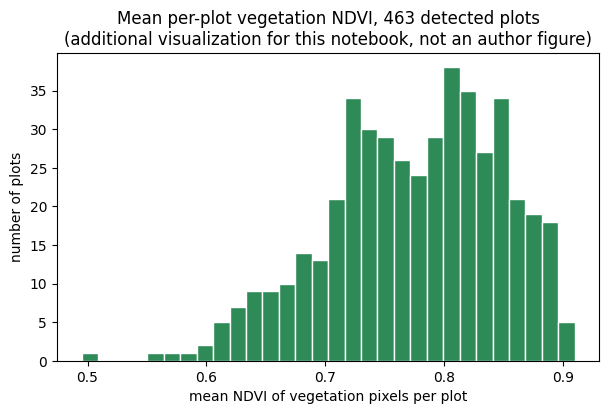

In [ ]:
print(plots[['vegetation_fraction', 'mean_ndvi_vegetation']].describe().round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(plots['mean_ndvi_vegetation'], bins=30, color='seagreen', edgecolor='white')
ax.set_xlabel('mean NDVI of vegetation pixels per plot')
ax.set_ylabel('number of plots')
ax.set_title(f'Mean per-plot vegetation NDVI, {len(plots)} detected plots\n'
             '(additional visualization for this notebook, not an author figure)')
plt.show()

## 9. Export the per-plot table

The full per-plot table (bounding-box vertices in the authors' `area2` convention: `X1, Y1, X2, Y2`, plus the pixel classification counts) is exported as CSV on the Colab VM for further use.

**日本語:** 全プロットの表（著者の `area2` 形式の頂点座標＋ピクセル分類カウント）を CSV として Colab 上に保存します。

In [ ]:
out = plots.copy()
out.rename(columns={'bbox_row0': 'Y1', 'bbox_col0': 'X1',
                    'bbox_row1': 'Y2', 'bbox_col1': 'X2'}, inplace=True)
out.to_csv('/content/detected_plots_ndvi_stats.csv', index=False)
print('saved /content/detected_plots_ndvi_stats.csv')
print('files in /content:')
for f in sorted(os.listdir('/content')):
    print(' ', f, os.path.getsize('/content/' + f), 'bytes')

saved /content/detected_plots_ndvi_stats.csv
files in /content:
  .config 4096 bytes
  20191129_40m_ndvi_CUT_BIN_027_FILTER_GRID1.tif 9482928 bytes
  detected_plots_ndvi_stats.csv 23029 bytes
  sample_data 4096 bytes


## 10. Interpretation, scope, and validation record

**What was executed (this run):** the authors' plot-detection subsection was ported from MATLAB to Python and run end-to-end on their own deposited sample grid: pinned byte-verified download → NDVI>0 mask → connected-component plot detection with bounding boxes and index labels (port of `ObjectsDetection.m`) → per-plot no-data/zero/vegetation pixel classification and mean vegetation NDVI (port of `Retrieving_PixelsInformation.m`).

**Differences from the authors' pipeline:**
- The binary mask is derived from NDVI > 0 instead of the absent RGB image (`im2bw` at 0.5); regions below 100 px are excluded. Both adaptations are documented above with their observed justification.
- The authors' plotting was MATLAB GUI output; here it is matplotlib. Units, pixel coordinates, and the `<0 / ==0 / >0` classification convention are preserved.

**Out of scope (materials not publicly deposited):** the K-means + Gaussian-KRR severity models (no fitted parameters, no orthomosaics), the NDVI-threshold regression on severity (severity table is public but the paired per-plot NDVI imagery is not), mixed-model BLUEs (R scripts not deposited), and genotype-ranking coincidence analysis.

**One-example caveat:** running this subsection on one sample grid does not verify the paper's dataset-level accuracy or its published R² / selection-coincidence values.

**Validation record:** executed on a fresh Google Colab CPU runtime; the sample was verified byte-identical to the pinned repository blob `196b5e7e654ebeb487ee97181e2e14dc7f3c226f` before use.

**References:**
- Paper: PLOS ONE 21(11):e0347446, DOI 10.1371/journal.pone.0347446 (CC BY).
- Author code: `hildomaclean/Plots-Potato-detection` @ commit `681f15bd24b1169776d15990c87ce29f8d1a90d1` (no license file; reproduced here as an attributed, adapted demonstration).

**日本語:** 本実行では、著者公開 MATLAB コードのプロット検出サブセクションを Python に移植し、著者提供サンプル画像で検出・ラベリング・プロット別統計抽出までを検証済みダウンロード込みで実行しました。RGB 由来マスク→NDVI>0 マスクへの適応と 100 px の最小面積は明示文書化済みです。K-means+KRR 等の重度推定モデルは学習済みパラメータと画像が公開されていないため対象外です。単一サンプルの実行であり、論文のデータセット規模の精度や R² の検証ではありません。